# Comparison with CLASS

This notebook checks DISCO-EB against CLASS for a cosmology with one massive neutrino. It compares the power spectra of the cold dark matter and the baryons at redshift 99, a common starting point for N-body simulations, and at redshift 0.

CLASS (`classy`), scipy and matplotlib are installed as part of the project's dev group.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from classy import Class
from scipy.interpolate import CubicSpline

from discoeb import LCDM_MNU, matter_power_spectrum, solve_eb

K = np.geomspace(1.0e-4, 1.0, 128)  # wave numbers, 1/Mpc
REDSHIFTS = (99.0, 0.0)

Let's set up an LCDM model with one massive neutrino and compare the matter power spectra at redshift 99 and 0:

In [2]:
h = 0.67742
OMEGA_M, OMEGA_B = 0.3099, 0.0488911  # matter (CDM plus baryons), and baryons
cosmology = LCDM_MNU.from_density_parameters(
    Omega_m=OMEGA_M,
    Omega_b=OMEGA_B,
    H_0=100.0 * h,
    A_s=2.1064e-9,
    n_s=0.96822,
    T_cmb=2.7255,
    Y_He=0.248,
    N_eff=2.046,  # the massless flavours
    N_mnu=1,
    m_nu=0.06,  # eV
)

DISCO-EB's solutions and CLASS's transfer functions are both per unit primordial curvature, so `matter_power_spectrum` turns either into a spectrum:

$$
P(k) = \frac{2 \pi^2}{k^3} A_s \left(\frac{k}{k_p}\right)^{n_s - 1} \delta_m(k)^2 ,
\qquad
\delta_m = \frac{\omega_c \delta_c + \omega_b \delta_b}{\omega_c + \omega_b} .
$$

In [6]:
PRIMORDIAL = dict(A_s=cosmology.A_s, n_s=cosmology.n_s, k_p=cosmology.k_p)
SPECIES = {
    "CDM": dict(omega_c=cosmology.omega_c, omega_b=0.0),
    "baryons": dict(omega_c=0.0, omega_b=cosmology.omega_b),
    "CDM + baryons": dict(omega_c=cosmology.omega_c, omega_b=cosmology.omega_b),
}

## DISCO-EB

The solve integrates in coordinates of the scale factor:

In [11]:
# One launch that saves at the scale factors of the two redshifts.
a = 1.0 / (1.0 + np.asarray(REDSHIFTS))  # ascending
values = solve_eb(cosmology, K, a, keep=("delta_c", "delta_b"), rtol=1.0e-5)
delta_c, delta_b = np.asarray(values[0])  # each (k, redshift)
disco = {
    name: matter_power_spectrum(
        K, delta_c=delta_c.T, delta_b=delta_b.T, **weights, **PRIMORDIAL
    )
    for name, weights in SPECIES.items()
}  # matter power spectra for each species and their sum, at each (redshift, k)

## CLASS

CLASS runs the same cosmology in the synchronous gauge, without reionization and with the full neutrino hierarchy.

In [8]:
# The same cosmology in CLASS, without reionization.
reference = Class()
reference.set(
    {
        "h": h,
        "Omega_b": OMEGA_B,
        "Omega_cdm": OMEGA_M - OMEGA_B,
        "T_cmb": cosmology.T_cmb,
        "YHe": cosmology.Y_He,
        "N_ur": cosmology.N_eff,
        "N_ncdm": 1,
        "m_ncdm": cosmology.m_nu,
        "reio_parametrization": "reio_none",
        "output": "dTk",
        "gauge": "synchronous",
        "P_k_max_1/Mpc": 1.1 * K[-1],
        "z_max_pk": max(REDSHIFTS),
        "k_per_decade_for_pk": 50,
        "k_per_decade_for_bao": 50,
        "ncdm_fluid_approximation": 3,  # none: integrate the full hierarchy
    }
)
reference.compute()

A cubic spline in $\ln k$ moves CLASS's transfer functions onto DISCO-EB's wave numbers. Linear interpolation would add wiggles of its own at the BAO scale.

In [9]:
classy = {name: [] for name in SPECIES}
for z in REDSHIFTS:
    transfer = reference.get_transfer(z)
    k_class = transfer["k (h/Mpc)"] * h
    d_c, d_b = (
        CubicSpline(np.log(k_class), transfer[c])(np.log(K)) for c in ("d_cdm", "d_b")
    )
    for name, weights in SPECIES.items():
        classy[name].append(
            matter_power_spectrum(K, delta_c=d_c, delta_b=d_b, **weights, **PRIMORDIAL)
        )

## Comparison

The solvers agree to well within 0.5%.

           species      z   max |P / P_CLASS - 1|
               CDM     99                2.57e-03
           baryons     99                3.69e-03
     CDM + baryons     99                2.70e-03
               CDM      0                2.88e-03
           baryons      0                2.89e-03
     CDM + baryons      0                2.88e-03


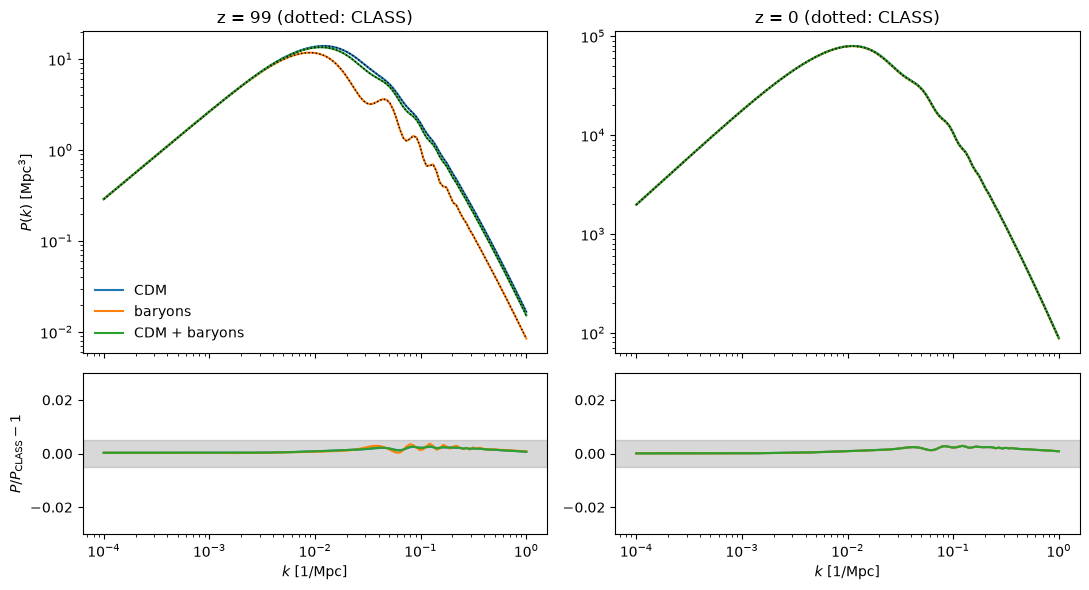

In [12]:
fig, axes = plt.subplots(
    2, len(REDSHIFTS), figsize=(11, 6), sharex=True, height_ratios=(2, 1)
)
print(f"{'species':>18}  {'z':>5}  {'max |P / P_CLASS - 1|':>22}")
for j, z in enumerate(REDSHIFTS):
    for color, name in zip(("C0", "C1", "C2"), disco):
        ratio = disco[name][j] / classy[name][j] - 1.0
        print(f"{name:>18}  {z:5.0f}  {np.abs(ratio).max():22.2e}")
        axes[0, j].loglog(K, disco[name][j], color=color, label=name)
        axes[0, j].loglog(K, classy[name][j], color="k", ls=":", lw=1)
        axes[1, j].semilogx(K, ratio, color=color)
    axes[0, j].set_title(f"z = {z:.0f} (dotted: CLASS)")
    axes[1, j].axhspan(-0.005, 0.005, color="gray", alpha=0.3)
    axes[1, j].set_ylim(-0.03, 0.03)
    axes[1, j].set_xlabel(r"$k$ [1/Mpc]")
axes[0, 0].set_ylabel(r"$P(k)$ [Mpc$^3$]")
axes[1, 0].set_ylabel(r"$P / P_\mathrm{CLASS} - 1$")
axes[0, 0].legend(frameon=False)
fig.tight_layout()
plt.show()